# E0: Is the probe trustworthy? (validation ladder + the A = 0 null test)

**Nothing big gets launched until this notebook passes.** It answers one question: *when the probe reports a recovered $\hat A$ for a trained model, how much of that can we believe?*

What is new compared with the old probe:

| old probe | this notebook |
|---|---|
| two stages, 12 probe pairs | **one joint least-squares fit**, 60 probe pairs ($10d$) |
| $\theta$ thrown away | **$\hat\theta$ recovered** from the per-pair intercepts |
| no fit check | **fidelity $R^2$**: how well "an LCL with this $\hat A$" explains the model at all |
| one probe draw | **bootstrap over probe pairs** gives a confidence interval |
| probed on ordinary slates only | **probe-invariance**: probe again on unusual slates and compare |
| negative control = context-free MLP (cannot fail) | **null test**: flexible models trained on $A=0$ data |

**Ladder** (each rung must behave as described before the next one is trusted):

- **V1** the generator's own score function gives $\hat A = A$, $\hat\theta=\theta$ exactly
- **V2** a hand-built attention network with $W_Q^\top W_K = A$ gives $\hat A = A$ exactly
- **V4** a *non-LCL* function (a saturating version of LCL) gives a visibly lower fidelity
- **V3** mean-pool and self-attention trained on $A=0$ data: how large is $\|\hat A\|_F$? This is the probe's false-positive floor. The oracle on the same data shows the pure statistical-noise floor.

Run the cells top to bottom, one at a time. Set `E0_QUICK=1` in the environment for a tiny run that only checks the code works.

## Setup and configuration

All the knobs are in this one cell. Defaults match the reference configuration of the main notebook ($d=6$, rank 2, $\|A\|_F=1$, slate size 5, 40,000 training sessions).

In [ ]:
import os, copy, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)

QUICK  = os.environ.get("E0_QUICK", "0") == "1"      # tiny run, only to check the code works
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = os.environ.get("E0_OUT", "e0_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

# --- ground truth / data (same as the main notebook) ---
D, RANK_A, A_SCALE, SLATE = 6, 2, 1.0, 5
N_TRAIN = 2000 if QUICK else 40000
N_VAL = N_EVAL = N_SHIFT = 500 if QUICK else 5000

# --- training (same protocol as the main notebook) ---
LR, MAX_EPOCHS, PATIENCE = 1e-2, (20 if QUICK else 300), 60

# --- probe ---
PROBE_K = 12 if QUICK else 10 * D      # number of probe pairs (10 d)
PROBE_N = 100 if QUICK else 500        # slates per probe pair
N_BOOT  = 20 if QUICK else 200         # bootstrap resamples of the probe pairs

SEEDS = [101, 202] if QUICK else [101, 202, 303, 404, 505]
PIPELINE_TAG = "e0-v1"

print(f"device={DEVICE} | quick={QUICK} | d={D} | probe: K={PROBE_K} pairs x {PROBE_N} slates | seeds={SEEDS}")

device=cuda | quick=False | d=6 | probe: K=60 pairs x 500 slates | seeds=[101, 202, 303, 404, 505]


## Data: ground truth, slates, choices, splits

Copied from the main notebook so the numbers are comparable. One addition: `A_scale=0` gives the **null world** ($A=0$, same $\theta$, same slates), which is what the null test trains on.

$$u_i(S) = (\theta + A\,y_S)^\top x_i, \qquad y_S=\tfrac1{|S|}\sum_{j\in S}x_j$$

In [ ]:
def make_ground_truth(d, rank_A, A_scale, seed):
    rng = np.random.default_rng(seed)
    theta = rng.normal(0, 1, size=d); theta /= np.linalg.norm(theta)
    U = rng.normal(0, 1, size=(d, rank_A)); V = rng.normal(0, 1, size=(d, rank_A))
    A_mat = U @ V.T
    A_mat = A_mat / np.linalg.norm(A_mat, ord="fro")
    return theta, A_scale * A_mat            # A_scale = 0  ->  the null world

def draw_slates(n, slate_size, d, seed):
    X = np.random.default_rng(seed).normal(0, 1, size=(n, slate_size, d))
    return X, X.mean(axis=1)

def simulate_choices(theta, A, X, seed):
    rng = np.random.default_rng(seed)
    y_S = X.mean(axis=1)
    util = np.einsum("nd,nsd->ns", theta[None, :] + y_S @ A.T, X)
    z = util - util.max(axis=1, keepdims=True)
    probs = np.exp(z); probs /= probs.sum(axis=1, keepdims=True)
    choices = np.clip((rng.random((X.shape[0], 1)) > probs.cumsum(axis=1)).sum(axis=1), 0, X.shape[1] - 1)
    return probs, choices

def make_shifted_slates(n_shift, slate_size, d, seed, oversample=20):
    pool = np.random.default_rng(seed).normal(0, 1, size=(n_shift * oversample, slate_size, d))
    keep = np.argsort(np.linalg.norm(pool.mean(axis=1), axis=1))[-n_shift:]
    return pool[keep]

def build_all_splits(theta, A, n_train, data_seed):
    X_all, _ = draw_slates(n_train + N_VAL + N_EVAL, SLATE, D, seed=data_seed)
    parts = {"train": X_all[:n_train],
             "val": X_all[n_train:n_train + N_VAL],
             "eval_in": X_all[n_train + N_VAL:],
             "eval_shift": make_shifted_slates(N_SHIFT, SLATE, D, seed=data_seed + 1)}
    out = {}
    for k, (name, Xp) in enumerate(parts.items()):
        probs, choices = simulate_choices(theta, A, Xp, seed=data_seed * 10 + k)
        out[name] = dict(X=Xp, probs=probs, choices=choices)
    return out

# quick look: the null world really has no context effect
theta_ref, A_ref = make_ground_truth(D, RANK_A, A_SCALE, seed=12345)
_, A_null = make_ground_truth(D, RANK_A, 0.0, seed=12345)
print("||A_ref||_F =", round(np.linalg.norm(A_ref), 4), "| ||A_null||_F =", np.linalg.norm(A_null))

||A_ref||_F = 1.0 | ||A_null||_F = 0.0


## The probe, rebuilt

**Idea (unchanged).** Fix a pair of items $(a,b)$ with $\delta=x_a-x_b$ and drop it into many slates whose other three items are fresh. Under LCL the score gap is

$$\Delta(S)=\theta^\top\delta+\delta^\top A\,y_S .$$

**What changes.**

1. For each pair we subtract that pair's average gap and average $y_S$. This removes everything that is constant for the pair, including any nonlinear *context-free* part of the model, so a model with no context effect gets a slope of exactly 0.
2. All pairs are then fitted **together** in one least squares for the 36 numbers of $A$ (not pair by pair and then again).
3. What was subtracted is the pair's intercept $c_k$. Under LCL, $c_k=\theta^\top\delta_k$, so $\hat\theta$ comes from regressing $c_k$ on $\delta_k$.
4. **Fidelity** $R^2_A$ is the share of the within-pair variation in the model's score gaps that "LCL with $\hat A$" explains. $R^2_\theta$ is the same for the intercepts. Low fidelity means $\hat A$ is a poor summary of what the model is doing. That is a finding, not a bug.
5. Per-pair sufficient statistics are stored, so the **bootstrap over probe pairs** is cheap.

In [ ]:
def run_probe(score_fn, K=PROBE_K, n_trials=PROBE_N, seed=7, shifted=False, oversample=10):
    # Collect per-pair statistics. score_fn: (n, S, d) float64 array -> (n, S) scores.
    # shifted=True keeps only the probe slates with the largest ||y_S|| (the unusual-slate regime).
    rng = np.random.default_rng(seed)
    d2 = D * D
    st = dict(G=np.zeros((K, d2, d2)), b=np.zeros((K, d2)), ss=np.zeros(K),
              mg=np.zeros(K), Yb=np.zeros((K, D)), Dl=np.zeros((K, D)))
    for k in range(K):
        x_a, x_b = rng.normal(size=(2, D))                  # in-distribution probe items
        n_gen = n_trials * (oversample if shifted else 1)
        fill = rng.normal(size=(n_gen, SLATE - 2, D))
        X = np.concatenate([np.broadcast_to(x_a, (n_gen, 1, D)),
                            np.broadcast_to(x_b, (n_gen, 1, D)), fill], axis=1)
        y = X.mean(axis=1)
        if shifted:
            keep = np.argsort(np.linalg.norm(y, axis=1))[-n_trials:]
            X, y = X[keep], y[keep]
        sc = score_fn(X)
        gap = sc[:, 0] - sc[:, 1]
        delta = x_a - x_b
        y_bar, gap_bar = y.mean(axis=0), gap.mean()
        Z = np.einsum("p,nq->npq", delta, y - y_bar).reshape(len(y), d2)   # column p*D+q  <->  A[p,q]
        g = gap - gap_bar
        st["G"][k], st["b"][k], st["ss"][k] = Z.T @ Z, Z.T @ g, g @ g
        st["mg"][k], st["Yb"][k], st["Dl"][k] = gap_bar, y_bar, delta
    return st

def fit_from_stats(st, idx):
    G, b = st["G"][idx].sum(0), st["b"][idx].sum(0)
    vecA = np.linalg.lstsq(G, b, rcond=None)[0]
    A_hat = vecA.reshape(D, D)
    Dl = st["Dl"][idx]
    c = st["mg"][idx] - np.einsum("kp,pq,kq->k", Dl, A_hat, st["Yb"][idx])   # = theta^T delta under LCL
    theta_hat = np.linalg.lstsq(Dl, c, rcond=None)[0]
    ss = st["ss"][idx].sum()
    ss_res = ss - 2 * vecA @ b + vecA @ G @ vecA
    fid_A = 1 - ss_res / ss if ss > 1e-12 else np.nan
    res = c - Dl @ theta_hat
    fid_theta = 1 - (res @ res) / (((c - c.mean()) ** 2).sum() + 1e-12)
    return A_hat, theta_hat, fid_A, fid_theta

def recovery_metrics(A_hat, theta_hat, A_true, theta_true):
    a, b = A_hat.ravel(), A_true.ravel()
    fro_hat, nb = np.linalg.norm(a), np.linalg.norm(b)
    out = dict(fro_hat=fro_hat)
    if nb > 1e-12:
        out.update(cosine=a @ b / (fro_hat * nb + 1e-12), rel_frob=np.linalg.norm(a - b) / nb, scale_ratio=fro_hat / nb)
    else:                                                    # null world: only the absolute size means anything
        out.update(cosine=np.nan, rel_frob=np.nan, scale_ratio=np.nan)
    out["theta_cos"] = theta_hat @ theta_true / (np.linalg.norm(theta_hat) * np.linalg.norm(theta_true) + 1e-12)
    out["theta_relerr"] = np.linalg.norm(theta_hat - theta_true) / np.linalg.norm(theta_true)
    return out

def probe_report(score_fn, A_true, theta_true, seed=7, n_boot=N_BOOT, with_shift=True):
    # Point estimate + bootstrap CI (over probe pairs) + fidelity + probe-invariance.
    st = run_probe(score_fn, seed=seed)
    K = len(st["ss"])
    A_hat, th_hat, fid_A, fid_th = fit_from_stats(st, np.arange(K))
    row = recovery_metrics(A_hat, th_hat, A_true, theta_true)
    row.update(fid_A=fid_A, fid_theta=fid_th)
    brng = np.random.default_rng(seed + 999)
    boots = []
    for _ in range(n_boot):
        Ab, thb, _, _ = fit_from_stats(st, brng.integers(0, K, size=K))
        boots.append(recovery_metrics(Ab, thb, A_true, theta_true))
    boots = pd.DataFrame(boots)
    for m in ["fro_hat", "cosine", "theta_cos"]:
        row[m + "_lo"], row[m + "_hi"] = np.nanpercentile(boots[m], [2.5, 97.5]) if boots[m].notna().any() else (np.nan, np.nan)
    if with_shift:                                           # probe again on unusual slates
        st2 = run_probe(score_fn, seed=seed + 1, shifted=True)
        A_sh = fit_from_stats(st2, np.arange(K))[0]
        row["inv_abs"] = np.linalg.norm(A_hat - A_sh)
        row["inv_rel"] = row["inv_abs"] / (np.linalg.norm(A_hat) + 1e-12)
    return row, A_hat, th_hat

## V1, V2, V4: probing functions whose answer we know

- **V1** the generator's own scoring rule. Expect cosine 1, scale ratio 1, $\hat\theta=\theta$, both fidelities 1.
- **V2** a hand-built attention network: scores $\theta^\top x_i+\frac1m\sum_j (W_Qx_i)\cdot(W_Kx_j)$ with $W_Q^\top W_K=A$ from an SVD. It is mathematically the same function as V1 but goes through a different code path, so it checks that "attention-shaped" models are read correctly.
- **V4** a *saturating* version, $\theta^\top x_i+\tfrac12\tanh(2\,x_i^\top A y_S)$. It is not LCL. A trustworthy probe should show **fidelity below 1** here (and a scale ratio that is not 1). If V4 reads fidelity 1.000, the fidelity check is not sensitive and cannot be used to say "this model is not LCL".

In [ ]:
theta_t, A_t = theta_ref, A_ref

def f_true(X):                                              # V1
    y = X.mean(axis=1)
    return np.einsum("nd,nsd->ns", theta_t[None, :] + y @ A_t.T, X)

U_, S_, Vt_ = np.linalg.svd(A_t)
Wq, Wk = np.sqrt(S_)[:, None] * U_.T, np.sqrt(S_)[:, None] * Vt_     # Wq^T Wk = A
def f_handbuilt_attention(X):                               # V2
    q, k = X @ Wq.T, X @ Wk.T
    pulls = np.einsum("nid,njd->nij", q, k)                 # x_i^T A x_j
    return X @ theta_t + pulls.mean(axis=2)                 # average over ALL j (y_S includes x_i)

def f_saturating(X):                                        # V4
    y = X.mean(axis=1)
    z = np.einsum("nd,nsd->ns", y @ A_t.T, X)               # x_i^T A y_S
    return X @ theta_t + 0.5 * np.tanh(2.0 * z)

rows = []
for name, fn in [("V1 generator's own score", f_true), ("V2 hand-built attention", f_handbuilt_attention),
                 ("V4 saturating (not LCL)", f_saturating)]:
    r, _, _ = probe_report(fn, A_t, theta_t, seed=7)
    rows.append(dict(rung=name, **r))
ladder = pd.DataFrame(rows).set_index("rung")
cols = ["fro_hat", "cosine", "rel_frob", "scale_ratio", "theta_cos", "theta_relerr", "fid_A", "fid_theta", "inv_rel"]
print(ladder[cols].round(4).to_string())

                          fro_hat  cosine  rel_frob  scale_ratio  theta_cos  theta_relerr   fid_A  fid_theta  inv_rel
rung                                                                                                                 
V1 generator's own score   1.0000  1.0000    0.0000       1.0000        1.0        0.0000  1.0000     1.0000   0.0000
V2 hand-built attention    1.0000  1.0000    0.0000       1.0000        1.0        0.0000  1.0000     1.0000   0.0000
V4 saturating (not LCL)    0.5424  0.9917    0.4674       0.5424        1.0        0.0085  0.8467     0.9982   0.1913


## Models and training (same protocol as the main notebook)

Mean-pool network, self-attention (1 layer, `d_model=32`, 2 heads, no dropout) and the oracle. Training is full-batch Adam, lr 0.01, early stopping on **validation NLL only**: the ground truth is never used to pick a checkpoint. Besides NLL we report **KL(true || model)** on `eval_in` and `eval_shift`. It is exact because the true choice probabilities of every evaluation slate are known.

The mean-pool width (87) is the one the main notebook matched to self-attention's 8,801 parameters.

In [ ]:
class MeanPoolNetwork(nn.Module):
    def __init__(self, d, hidden=87):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * d, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, X):
        y = X.mean(dim=1, keepdim=True).expand(-1, X.shape[1], -1)
        return self.net(torch.cat([X, y], dim=-1)).squeeze(-1)

class SelfAttentionModel(nn.Module):
    def __init__(self, d, d_model=32, n_heads=2, n_layers=1, dropout=0.0):
        super().__init__()
        self.embed = nn.Linear(d, d_model)
        layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=2 * d_model,
                                           dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, 1)
    def forward(self, X):
        return self.head(self.encoder(self.embed(X))).squeeze(-1)

class LCLOracle(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.theta = nn.Parameter(torch.randn(d) * 0.1)
        self.A = nn.Parameter(torch.randn(d, d) * 0.1)
    def forward(self, X):
        y = X.mean(dim=1)
        return torch.einsum("nd,nsd->ns", self.theta.unsqueeze(0) + y @ self.A.T, X)

MODELS = {"mean_pool_network": lambda: MeanPoolNetwork(D), "self_attention": lambda: SelfAttentionModel(D),
          "oracle": lambda: LCLOracle(D)}
for n, mk in MODELS.items():
    print(f"{n:<20}{sum(p.numel() for p in mk().parameters()):>8} parameters")

def to_dev(split):
    return dict(X=torch.tensor(split["X"], dtype=torch.float32, device=DEVICE),
                y=torch.tensor(split["choices"], dtype=torch.long, device=DEVICE),
                p=torch.tensor(split["probs"], dtype=torch.float32, device=DEVICE))

@torch.no_grad()
def eval_split(model, s):
    was = model.training; model.eval()
    logq = torch.log_softmax(model(s["X"]), dim=1)
    nll = -logq.gather(1, s["y"][:, None]).mean().item()
    kl = (s["p"] * (torch.log(s["p"] + 1e-12) - logq)).sum(1).mean().item()
    model.train(was)
    return nll, kl

def train_early_stop(model, tr, va):
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    lossf = nn.CrossEntropyLoss()
    best, best_state, best_ep = float("inf"), None, 0
    for ep in range(MAX_EPOCHS):
        model.train(); opt.zero_grad()
        lossf(model(tr["X"]), tr["y"]).backward(); opt.step()
        v = eval_split(model, va)[0]
        if v < best: best, best_ep, best_state = v, ep, copy.deepcopy(model.state_dict())
        if ep - best_ep >= PATIENCE: break
    model.load_state_dict(best_state)
    return ep + 1, best_ep, best

def score_fn_of(model):
    def f(X):
        model.eval()
        with torch.no_grad():
            return model(torch.tensor(X, dtype=torch.float32, device=DEVICE)).double().cpu().numpy()
    return f

mean_pool_network       8875 parameters
self_attention          8801 parameters
oracle                    42 parameters


## V3: the null test (the one your professor will ask for first)

For each seed we build **two worlds with the same $\theta$ and the same slates**: a *context* world ($\|A\|_F=1$) and a *null* world ($A=0$). Each model is trained in both worlds and probed.

What to read from the result:

- On **null** data the true answer is $\hat A=0$, so $\|\hat A\|_F$ **is the false-positive floor** of the model + probe combination. The **oracle** on null data shows the unavoidable statistical-noise part of that floor (it has the right form and can only be wrong through finite data). Whatever self-attention shows *beyond* the oracle is invented by the flexible architecture.
- On **context** data we get the real recovery, with a CI from the bootstrap, plus $\hat\theta$, fidelity and probe-invariance.
- The floor must be small next to the smallest effect size you plan to report. If it is not, the later sweeps cannot be interpreted below that effect size.

The cell saves one CSV row per (world, model, seed) and skips rows already saved, so if the session dies, run it again.

In [ ]:
CSV = os.path.join(OUT_DIR, "e0_null_test.csv")

def load_results():
    if not os.path.exists(CSV): return pd.DataFrame()
    df = pd.read_csv(CSV)
    return df[df.pipeline == PIPELINE_TAG].reset_index(drop=True) if "pipeline" in df else pd.DataFrame()

def run_world(world, seed):
    a_scale = A_SCALE if world == "context" else 0.0
    theta_c, A_c = make_ground_truth(D, RANK_A, a_scale, seed)
    splits = {k: to_dev(v) for k, v in build_all_splits(theta_c, A_c, N_TRAIN, data_seed=seed + 1).items()}
    rows = []
    for name, make in MODELS.items():
        torch.manual_seed(seed)
        model = make().to(DEVICE)
        epochs, best_ep, val_nll = train_early_stop(model, splits["train"], splits["val"])
        rep, A_hat, th_hat = probe_report(score_fn_of(model), A_c, theta_c, seed=7)
        nll_in, kl_in = eval_split(model, splits["eval_in"])
        nll_sh, kl_sh = eval_split(model, splits["eval_shift"])
        rows.append(dict(data=world, model=name, seed=seed, epochs_run=epochs, best_epoch=best_ep, val_nll=val_nll,
                         nll_in=nll_in, kl_in=kl_in, nll_shift=nll_sh, kl_shift=kl_sh, **rep, pipeline=PIPELINE_TAG))
    return rows

t0 = time.time()
done = load_results()
done_keys = set(zip(done.data, done.seed)) if len(done) else set()
for seed in SEEDS:
    for world in ["no_effect", "context"]:
        if (world, seed) in done_keys: continue
        rows = run_world(world, seed)
        pd.DataFrame(rows).to_csv(CSV, mode="a", header=not os.path.exists(CSV), index=False)
        print(f"saved: world={world:<8} seed={seed}  ({time.time() - t0:.0f}s elapsed)")
res = load_results()
print(len(res), "rows in", CSV)

saved: world=no_effect seed=101  (19s elapsed)
saved: world=context  seed=101  (34s elapsed)
saved: world=no_effect seed=202  (47s elapsed)
saved: world=context  seed=202  (60s elapsed)
saved: world=no_effect seed=303  (71s elapsed)
saved: world=context  seed=303  (89s elapsed)
saved: world=no_effect seed=404  (102s elapsed)
saved: world=context  seed=404  (119s elapsed)
saved: world=no_effect seed=505  (129s elapsed)
saved: world=context  seed=505  (142s elapsed)
30 rows in e0_outputs/e0_null_test.csv


## Reading the null test

First the raw numbers, then the headline: for each model, the floor on null data next to the recovered size on context data.

In [ ]:
cols = ["fro_hat", "cosine", "rel_frob", "theta_cos", "fid_A", "fid_theta", "inv_rel", "kl_in", "kl_shift", "best_epoch"]
print(res.groupby(["data", "model"])[cols].agg(["mean", "std"]).round(4).to_string())
print()
print(f"{'model':<20}{'floor ||A_hat||_F on A=0':>28}{'||A_hat||_F with real effect':>32}{'floor / effect':>16}")
for m in MODELS:
    fl = res[(res.data == "no_effect") & (res.model == m)].fro_hat
    ef = res[(res.data == "context") & (res.model == m)].fro_hat
    print(f"{m:<20}{fl.mean():>16.3f} +- {fl.std():<7.3f}{ef.mean():>20.3f} (true 1.000){fl.mean() / ef.mean():>12.3f}")
print("\nseeds per cell:", res.groupby(["data", "model"]).seed.nunique().to_dict())

                            fro_hat          cosine         rel_frob         theta_cos           fid_A         fid_theta         inv_rel           kl_in         kl_shift         best_epoch         
                               mean     std    mean     std     mean     std      mean     std    mean     std      mean     std    mean     std    mean     std     mean     std       mean      std
data      model                                                                                                                                                                                      
context   mean_pool_network  0.9540  0.0652  0.9893  0.0017   0.1603  0.0148    0.9992  0.0008  0.9321  0.0103    0.9943  0.0009  0.1322  0.0125  0.0050  0.0007   0.0106  0.0017       46.2  12.7358
          oracle             1.0046  0.0200  0.9958  0.0010   0.0930  0.0118    0.9999  0.0001  1.0000  0.0000    1.0000  0.0000  0.0000  0.0000  0.0007  0.0002   0.0014  0.0003      158.6  68.9369
          

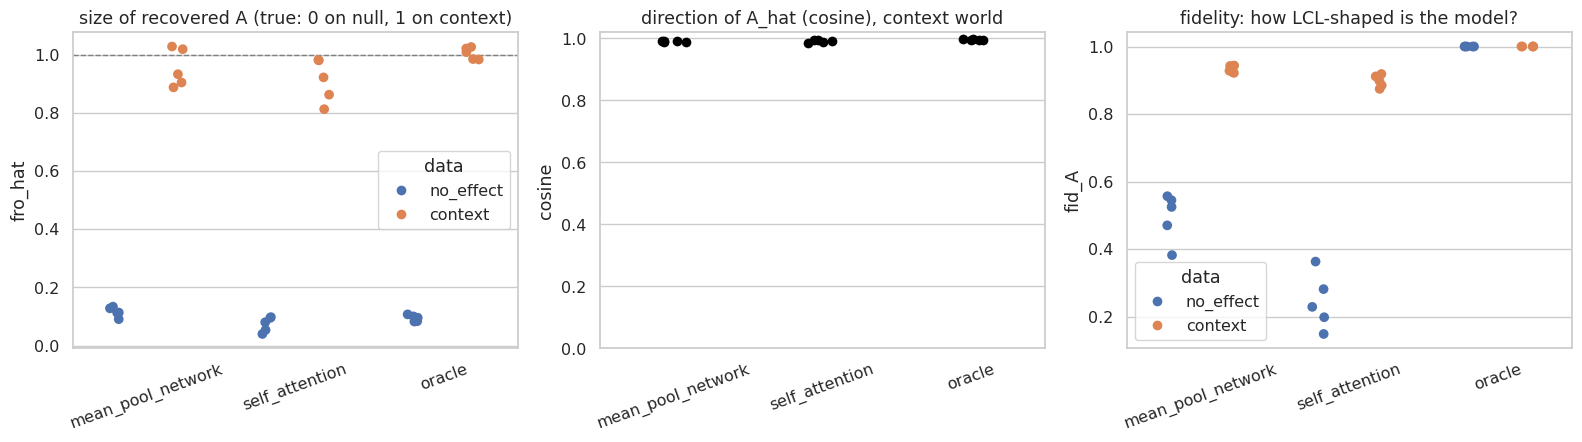

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
order = list(MODELS)
sns.stripplot(data=res, x="model", y="fro_hat", hue="data", order=order, dodge=True, ax=axes[0], size=7)
axes[0].axhline(1.0, color="gray", ls="--", lw=1); axes[0].set_title("size of recovered A (true: 0 on null, 1 on context)")
sns.stripplot(data=res[res.data == "context"], x="model", y="cosine", order=order, ax=axes[1], color="black", size=7)
axes[1].set_title("direction of A_hat (cosine), context world"); axes[1].set_ylim(0, 1.02)
sns.stripplot(data=res, x="model", y="fid_A", hue="data", order=order, dodge=True, ax=axes[2], size=7)
axes[2].set_title("fidelity: how LCL-shaped is the model?")
for ax in axes: ax.tick_params(axis="x", rotation=20); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "e0_null_test.png"), dpi=150); plt.show()

## What to do with the result

- **V1 and V2 not at 1.000** means a bug in the probe. Stop and fix before anything else.
- **V4 fidelity still 1.000** means the fidelity check cannot tell LCL from non-LCL. Do not use fidelity as evidence in the report.
- **Null floor of self-attention clearly above the oracle's** means flexible models invent context effects of that size. Every recovery number below that size must be reported as indistinguishable from zero. Paste these tables back and we decide the reporting threshold together.
- **Null floor tiny next to the effect** means the probe can be trusted at this effect size, and the next step is to freeze the protocol and run the pilots for E1 and E2.